# Q&A: Trend, random forest, and LASSO
**ECON 422**

**Q2.** What are the cases in which you will do a time series and random forest model vs. a time series and lasso model?

**Q3.** Why is it more beneficial to combine both instead of just doing forecasting on machine learning individually and then comparing the results?

We answer in four parts: **A2(i)** random forest with and without an explicit trend; **A2(ii)** which residual learner suits which DGP; **A3(1)** why consider classical models; **A3(2)** why combine RF and LASSO rather than choose only one.

Here, “trend + ML” means **fit a linear trend, then use ML to predict its residuals**. Merely including time as an RF predictor does not impose a trend. Run cells in order. Requires `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.

In A3(2), the classical trend is held fixed across forecasts. The new comparison is **one ML learner versus a weighted combination of two ML learners**.

## A2(i). Random forest with and without an explicit trend
Start with one simple DGP:
$$
y_t=5+0.10t+\varepsilon_t,\qquad \varepsilon_t\overset{\mathrm{iid}}{\sim}N(0,0.5^2).
$$
Fit on months $t=0,\ldots,79$ and forecast months $80,\ldots,119$.

- **RF without an explicit trend:** predict $y_t$ directly from $t$. It has time as an input, but no rule that continues a straight line.
- **Trend + RF:** estimate $\widehat a+\widehat b t$, fit RF to the training residuals, and add its correction to the trend forecast.

With time as the only predictor, all future dates pass the same learned tree cutoffs. The standalone RF forecast is therefore flat. The hybrid retains the estimated trend even though its RF correction is flat. **The classical component supplies the extrapolation rule.**

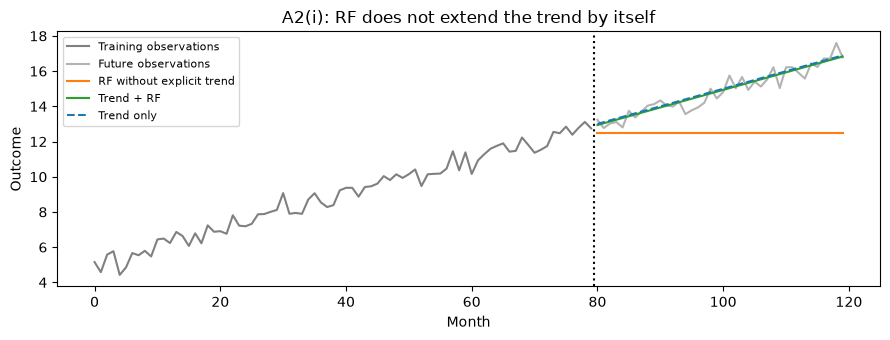

Trend only    0.405
RF only       2.679
Trend + RF    0.392
Name: Future RMSE, dtype: float64


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
t = np.arange(120)
Z = t.reshape(-1, 1)
mean_y = 5 + 0.10 * t
y = mean_y + rng.normal(scale=0.5, size=len(t))
cut = 80

def new_rf():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                 random_state=42)

def new_lasso():
    return make_pipeline(StandardScaler(), Lasso(alpha=0.05, max_iter=10000))

def rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred)**2))

trend = LinearRegression().fit(Z[:cut], y[:cut])
rf = new_rf().fit(Z[:cut], y[:cut])
residuals = y[:cut] - trend.predict(Z[:cut])
residual_rf = new_rf().fit(Z[:cut], residuals)
trend_pred = trend.predict(Z[cut:])
rf_pred = rf.predict(Z[cut:])
hybrid_pred = trend_pred + residual_rf.predict(Z[cut:])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t[:cut], y[:cut], color="gray", label="Training observations")
ax.plot(t[cut:], y[cut:], color="0.7", label="Future observations")
ax.plot(t[cut:], rf_pred, color="tab:orange", label="RF without explicit trend")
ax.plot(t[cut:], hybrid_pred, color="tab:green", label="Trend + RF")
ax.plot(t[cut:], trend_pred, "--", color="tab:blue", label="Trend only")
ax.axvline(cut - 0.5, color="black", linestyle=":")
ax.set(xlabel="Month", ylabel="Outcome", title="A2(i): RF does not extend the trend by itself")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pure_scores = {"Trend only": rmse(y[cut:], trend_pred),
               "RF only": rmse(y[cut:], rf_pred),
               "Trend + RF": rmse(y[cut:], hybrid_pred)}
print(pd.Series(pure_scores, name="Future RMSE").round(3))

## A2(ii). When is trend + RF or trend + LASSO better?
Now add observed predictors. We compare **two specific DGPs**, each with the same trend and noise:
$$
y_t=5+0.04t+g(\mathbf x_t)+\varepsilon_t,\qquad
\varepsilon_t\overset{\mathrm{iid}}{\sim}N(0,0.5^2).
$$
There are 20 predictors, independently drawn from $\operatorname{Uniform}(-1,1)$ across variables and dates. Only the first two matter. Assume their values are known at each forecast date; otherwise they would need to be forecast or replaced with available lags.

| DGP | Exact additional signal | Expected advantage |
|---|---|---|
| Sparse linear | $g(\mathbf x_t)=3x_{1t}-2x_{2t}$ | **Trend + LASSO:** a few linear effects among many candidates. |
| Nonlinear thresholds | $g(\mathbf x_t)=3\operatorname{sgn}(x_{1t})+2\operatorname{sgn}(x_{2t})+2\operatorname{sgn}(x_{1t})\operatorname{sgn}(x_{2t})$ | **Trend + RF:** threshold effects and an interaction that the supplied linear LASSO features omit. |

Here $\operatorname{sgn}(x)$ is $-1$ below zero and $+1$ above zero; an exact zero has probability zero. Both signals have mean zero, so the trend can be estimated from $y_t$ without a systematic contribution from the independent predictors.

Both hybrids use the same steps:
$$
\widehat y_t^{\mathrm{trend}}=\widehat a+\widehat b t,\quad
\widehat r_t=y_t-\widehat y_t^{\mathrm{trend}},\quad
\widehat y_t^{\mathrm{trend+ML}}=\widehat a+\widehat b t+\widehat g_{\mathrm{ML}}(\mathbf x_t).
$$
The residual learners receive the 20 predictors. Standalone ML receives time **and** those predictors. LASSO is linear in its supplied features; adding the correct threshold and interaction features could change the comparison.

**Evaluation:** fit on the first 420 dates, compare the two hybrids on the next 140, then refit on all 560 earlier dates and evaluate the last 140. Settings are fixed in advance, not tuned on final test results. The rankings below are illustrative, not guarantees for every sample.

In [2]:
rng = np.random.default_rng(123)
N = 700
time = np.arange(N)
X = rng.uniform(-1, 1, size=(N, 20))
noise = rng.normal(scale=0.5, size=N)
s1, s2 = np.sign(X[:, 0]), np.sign(X[:, 1])
signals = {
    "Sparse linear": 3 * X[:, 0] - 2 * X[:, 1],
    "Nonlinear thresholds": 3 * s1 + 2 * s2 + 2 * s1 * s2
}
train_end, test_start = 420, 560

def forecast_models(y_case, end, future):
    time_fit = time[:end].reshape(-1, 1)
    time_future = time[future].reshape(-1, 1)
    classical = LinearRegression().fit(time_fit, y_case[:end])
    base = classical.predict(time_future)
    residuals = y_case[:end] - classical.predict(time_fit)
    rf_res = new_rf().fit(X[:end], residuals)
    lasso_res = new_lasso().fit(X[:end], residuals)
    full_X = np.column_stack([time, X])
    rf_only = new_rf().fit(full_X[:end], y_case[:end])
    lasso_only = new_lasso().fit(full_X[:end], y_case[:end])
    return {
        "Trend only": base,
        "RF only": rf_only.predict(full_X[future]),
        "LASSO only": lasso_only.predict(full_X[future]),
        "Trend + RF": base + rf_res.predict(X[future]),
        "Trend + LASSO": base + lasso_res.predict(X[future])
    }

rows = []
case_forecasts = {}
for case, signal in signals.items():
    y_case = 5 + 0.04 * time + signal + noise
    val = slice(train_end, test_start)
    test = slice(test_start, N)
    val_pred = forecast_models(y_case, train_end, val)
    val_scores = {m: rmse(y_case[val], p) for m, p in val_pred.items()}
    hybrids = ["Trend + RF", "Trend + LASSO"]
    chosen = min(hybrids, key=lambda m: val_scores[m])
    test_pred = forecast_models(y_case, test_start, test)
    case_forecasts[case] = {
        "y_val": y_case[val], "y_test": y_case[test],
        "validation": val_pred, "test": test_pred
    }
    for model in test_pred:
        rows.append({"DGP": case, "Model": model,
                     "Validation RMSE": val_scores[model],
                     "Test RMSE": rmse(y_case[test], test_pred[model]),
                     "Chosen hybrid": model == chosen})
results = pd.DataFrame(rows)
hybrid_results = results[results["Model"].isin(["Trend + RF", "Trend + LASSO"])]
print(hybrid_results.round(3).to_string(index=False))

                 DGP         Model  Validation RMSE  Test RMSE  Chosen hybrid
       Sparse linear    Trend + RF            0.751      0.547          False
       Sparse linear Trend + LASSO            0.658      0.502           True
Nonlinear thresholds    Trend + RF            1.013      0.830           True
Nonlinear thresholds Trend + LASSO            2.800      2.697          False


## A3(1). Why consider a classical model at all, rather than ML alone?
Return to **A2(i)**. Its true predictable component is just $5+0.10t$. A classical linear trend estimates it with two coefficients. It both captures the structure efficiently and continues it into the future.

The standalone RF may approximate the historical relationship but cannot extend the rising line beyond the training time range. The hybrid can extend the line, yet its residual learner has no additional true signal to discover. It may add noise.

**Lesson:** with the same amount of training data, an appropriate classical model can be a strong forecaster. Extra flexibility is not automatically useful, and good historical fit does not ensure good extrapolation. LASSO with time as a feature can extrapolate a linear trend, so the RF limitation is not shared by all ML methods.

Read the RMSE values printed in A2(i): compare **trend only** with **RF only** and **trend + RF**. This answers why a classical benchmark is worth considering.

## A3(2). Why combine RF and LASSO instead of using only one?
**Different learners can make different mistakes.** LASSO favors linear relationships with shrinkage, whereas RF can capture nonlinear patterns and interactions. If their forecast errors offset one another, averaging can reduce squared forecast error. If both make the same mistakes, combining may add little.

We retain the two DGPs in A2(ii) and add a third, mixed-signal DGP below. To focus on the choice of **ML learner**, all forecasts retain the **same fitted trend**. We compare:

- Trend + RF: one residual learner.
- Trend + LASSO: one residual learner.
- Trend + RF/LASSO ensemble: a weighted average of their residual predictions.

Write the ensemble as
$$
\widehat y_t^{\mathrm E}
=\widehat a+\widehat b t
+w\widehat g_{\mathrm{RF}}(\mathbf x_t)
+(1-w)\widehat g_{\mathrm{LASSO}}(\mathbf x_t),\qquad 0\leq w\leq1.
$$
Equivalently, because the trend is shared,
$$
\widehat y_t^{\mathrm E}
=w\widehat y_t^{\mathrm{trend+RF}}
+(1-w)\widehat y_t^{\mathrm{trend+LASSO}}.
$$
The trend is counted **once**, not twice. Here $w=1$ uses only RF, $w=0$ uses only LASSO, and an interior weight combines both. This is forecast averaging, not fitting a single model with both algorithms.

### How we choose the weight
Use only validation observations to select $w$ from $\{0,0.01,\ldots,1\}$ by minimizing validation RMSE. Then hold this weight fixed, refit the two learners on training + validation as in A2(ii), and evaluate the combined forecast on the final test period. We also select the better **single** learner using validation data for a fair comparison with model selection.

**Combining is an option, not a guarantee.** The candidate weights include both individual forecasts, so the best grid weight cannot have higher validation RMSE than either endpoint. This does **not** guarantee lower test RMSE: a weight chosen on validation can overfit that period. The selected weight may also put all weight on one learner, indicating that this validation sample provides no reason to mix them.

The same weighted-average idea applies to standalone RF and LASSO forecasts; we retain a common trend here to isolate the benefit of combining the ML learners.

### A third example: complementary strengths
Keep the same trend, predictor distribution, noise, sample split, and learner settings, but use
$$
y_t=5+0.04t+
\underbrace{3x_{1t}-2x_{2t}}_{\text{linear signal}}
+\underbrace{2\operatorname{sgn}(x_{3t})}_{\text{nonlinear threshold}}
+\varepsilon_t.
$$
LASSO represents the linear part directly, but only approximates the threshold using a linear feature. RF can capture the threshold while its piecewise-constant predictions may approximate the linear part less efficiently. Their errors can therefore differ, giving a weighted combination an opportunity to improve on both.

All forecasts include the same classical trend.
Weights and single-learner choices use validation data only:
                 DGP  RF weight  LASSO weight Chosen single learner  Chosen single: test RMSE  Ensemble: test RMSE
       Sparse linear       0.00          1.00                 LASSO                     0.502                0.502
Nonlinear thresholds       1.00          0.00                    RF                     0.830                0.830
  Linear + nonlinear       0.87          0.13                    RF                     0.715                0.683

Final test comparison:
                 DGP ML learner(s)  Test RMSE
       Sparse linear            RF      0.547
       Sparse linear         LASSO      0.502
       Sparse linear    RF + LASSO      0.502
Nonlinear thresholds            RF      0.830
Nonlinear thresholds         LASSO      2.697
Nonlinear thresholds    RF + LASSO      0.830
  Linear + nonlinear            RF      0.715
  Linear + nonlinear         LASSO     

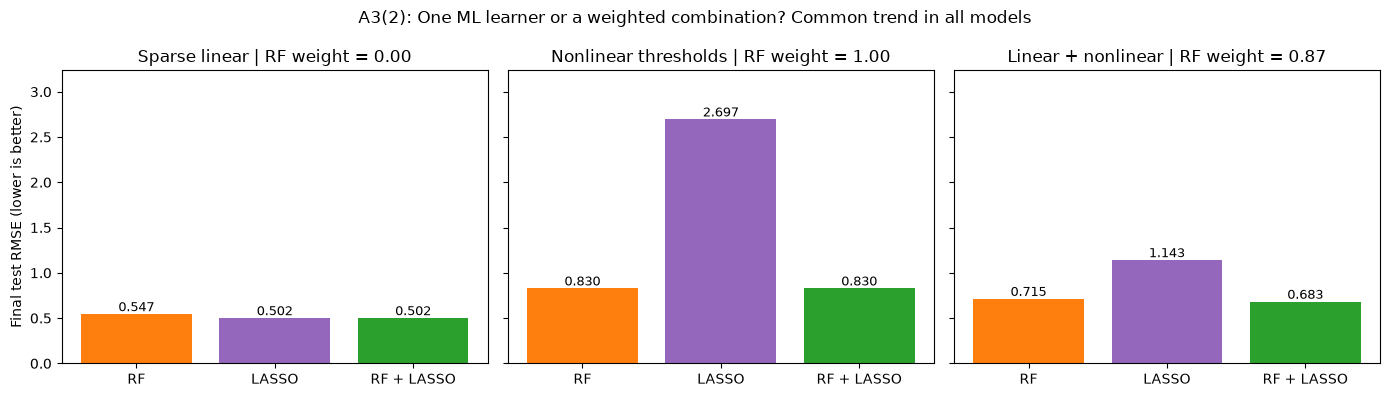

In [3]:
# Add a mixed-signal example; keep the existing two cases unchanged.
mixed_signal = 3 * X[:, 0] - 2 * X[:, 1] + 2 * np.sign(X[:, 2])
y_mixed = 5 + 0.04 * time + mixed_signal + noise
case_forecasts["Linear + nonlinear"] = {
    "y_val": y_mixed[train_end:test_start],
    "y_test": y_mixed[test_start:],
    "validation": forecast_models(y_mixed, train_end, slice(train_end, test_start)),
    "test": forecast_models(y_mixed, test_start, slice(test_start, N))
}

weights = np.linspace(0, 1, 101)
ensemble_rows = []
selection_rows = []
for case, saved in case_forecasts.items():
    val_rf = saved["validation"]["Trend + RF"]
    val_lasso = saved["validation"]["Trend + LASSO"]
    val_errors = [rmse(saved["y_val"], w * val_rf + (1 - w) * val_lasso)
                  for w in weights]
    w = weights[np.argmin(val_errors)]
    chosen_single = ("Trend + RF" if rmse(saved["y_val"], val_rf)
                     < rmse(saved["y_val"], val_lasso) else "Trend + LASSO")
    test_rf = saved["test"]["Trend + RF"]
    test_lasso = saved["test"]["Trend + LASSO"]
    test_ensemble = w * test_rf + (1 - w) * test_lasso
    final_forecasts = {"RF": test_rf, "LASSO": test_lasso,
                       "RF + LASSO": test_ensemble}
    for learner, pred in final_forecasts.items():
        ensemble_rows.append({"DGP": case, "ML learner(s)": learner,
                              "Test RMSE": rmse(saved["y_test"], pred)})
    selection_rows.append({
        "DGP": case, "RF weight": w, "LASSO weight": 1 - w,
        "Chosen single learner": chosen_single.replace("Trend + ", ""),
        "Chosen single: test RMSE": rmse(saved["y_test"], saved["test"][chosen_single]),
        "Ensemble: test RMSE": rmse(saved["y_test"], test_ensemble)
    })
    assert min(val_errors) <= min(val_errors[0], val_errors[-1]) + 1e-12

ensemble_results = pd.DataFrame(ensemble_rows)
selection_results = pd.DataFrame(selection_rows)
print("All forecasts include the same classical trend.")
print("Weights and single-learner choices use validation data only:")
print(selection_results.round(3).to_string(index=False))
print("\nFinal test comparison:")
print(ensemble_results.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, case in zip(axes, case_forecasts):
    table = ensemble_results[ensemble_results["DGP"] == case]
    values = table["Test RMSE"].to_numpy()
    ax.bar(table["ML learner(s)"], values,
           color=["tab:orange", "tab:purple", "tab:green"])
    for i, value in enumerate(values):
        ax.text(i, value + 0.03, f"{value:.3f}", ha="center", fontsize=9)
    w = selection_results.loc[selection_results["DGP"] == case, "RF weight"].iloc[0]
    ax.set_title(f"{case} | RF weight = {w:.2f}")
    ax.set_ylim(0, ensemble_results["Test RMSE"].max() * 1.2)
axes[0].set_ylabel("Final test RMSE (lower is better)")
fig.suptitle("A3(2): One ML learner or a weighted combination? Common trend in all models")
plt.tight_layout()
plt.show()

### Key Takeaways
**A2(i):** explicit trend + RF can continue a trend; RF with time alone cannot.

**A2(ii):** choose the residual learner according to the remaining signal: sparse linear effects favor LASSO; nonlinear thresholds and interactions may favor RF with the features used here.

**A3(1):** a classical model deserves consideration when its structure matches the DGP.

**A3(2):** RF and LASSO may make complementary errors, so combining their predictions can help. Choose weights on validation data and assess them on future test data. An endpoint weight selects one learner; an interior weight mixes both. A combined forecast is not guaranteed to beat the better individual method.

**Read the output:** does validation favor a mixture or a single learner in each DGP? Does the ensemble improve on the validation-selected single learner on the final test? Explain any difference between validation and test performance.

**Results for the supplied seed:** the sparse-linear case selects LASSO alone, and the nonlinear-threshold case selects RF alone. In the new mixed case, validation selects **87% RF + 13% LASSO**. Test RMSE is approximately **0.715 for RF**, **1.143 for LASSO**, and **0.683 for the combination**. The combination improves on the better single learner by about **4.4%** in this realization. The weight was not selected using test errors.

The improvement is modest and sample-specific. The three cases together illustrate both outcomes: sometimes choosing one learner suffices; sometimes combining complementary forecasts helps.